# 01.7 · Plotting: the six charts you actually need

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/01-working-with-data/07-plotting/lesson.ipynb)

Read the [README](README.md) first. We check the two by-hand charts, then draw all six on ShopWave data, each with the one finding it reveals.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
sns.set_theme(style="whitegrid")

## 1. By hand, checked: eight order values

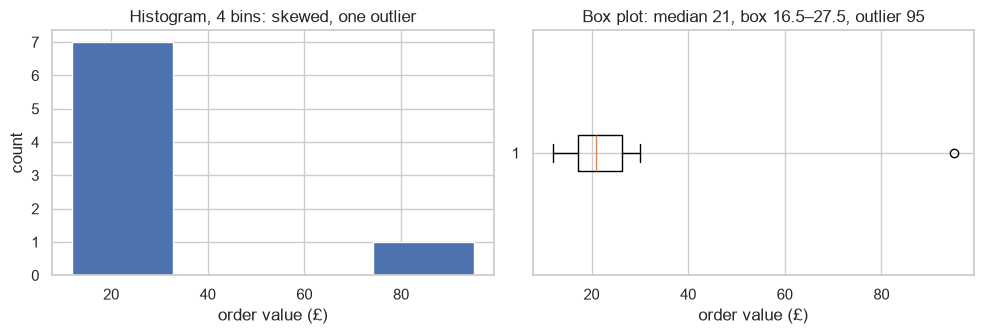

bin edges: [12.   32.75 53.5  74.25 95.  ]
counts:    [7 0 0 1]
Q1, median, Q3: [17.25 21.   26.25]


In [2]:
values = np.array([12, 15, 18, 20, 22, 25, 30, 95])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.hist(values, bins=4, edgecolor="white")
ax1.set(title="Histogram, 4 bins: skewed, one outlier", xlabel="order value (£)", ylabel="count")
ax2.boxplot(values, orientation="horizontal")
ax2.set(title="Box plot: median 21, box 16.5–27.5, outlier 95", xlabel="order value (£)")
plt.tight_layout(); plt.show()

print("bin edges:", np.histogram(values, bins=4)[1].round(2))
print("counts:   ", np.histogram(values, bins=4)[0])
print("Q1, median, Q3:", np.percentile(values, [25, 50, 75]))

Bin edges 12, 32.75, 53.5, 74.25, 95 and counts 7, 0, 0, 1, as calculated. NumPy's quartiles (17.25, 21, 26.25) differ slightly from the paper method (16.5, 21, 27.5): NumPy interpolates between sorted values, the paper method takes medians of the halves. There are several percentile conventions; on tiny samples they differ, on thousands of rows they agree. The box plot still shows 95 as the single outlier either way.

## 2. The real data

In [3]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()

(541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")

541,910 rows → 392,693 after cleaning


In [5]:
sales["month"] = sales["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
monthly = sales.groupby("month")["Revenue"].sum()
by_country = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
order_values = sales.groupby("Invoice")["Revenue"].sum()
customers = sales.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
customers["days_active"] = (customers["last_order"] - customers["first_order"]).dt.days
customers["avg_order"] = customers["spend"] / customers["orders"]

## 3. Line: how does revenue change over time?

The table from 01.6 had thirteen numbers. The chart has one message.

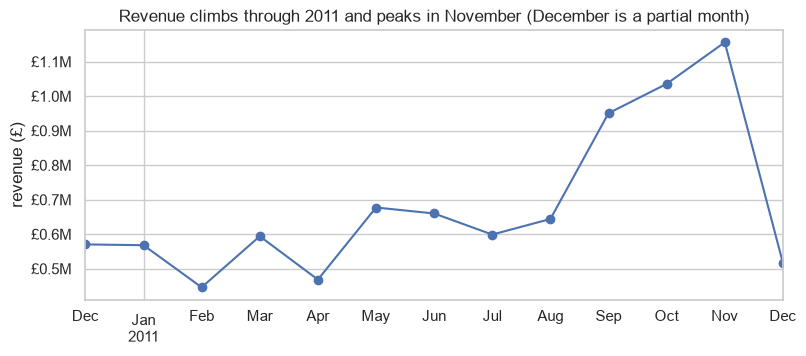

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
monthly.plot(ax=ax, marker="o")
ax.set(title="Revenue climbs through 2011 and peaks in November (December is a partial month)",
       xlabel="", ylabel="revenue (£)")
ax.yaxis.set_major_formatter(lambda v, _: f"£{v/1e6:.1f}M")
plt.show()

**Finding:** growth plus strong seasonality. The December drop is an artefact: the data ends on 9 December. A chart made you check the date range; a table would not have.

## 4. Bar: how do categories compare?

Horizontal bars so long country names stay readable. Sorted, so the eye reads a ranking.

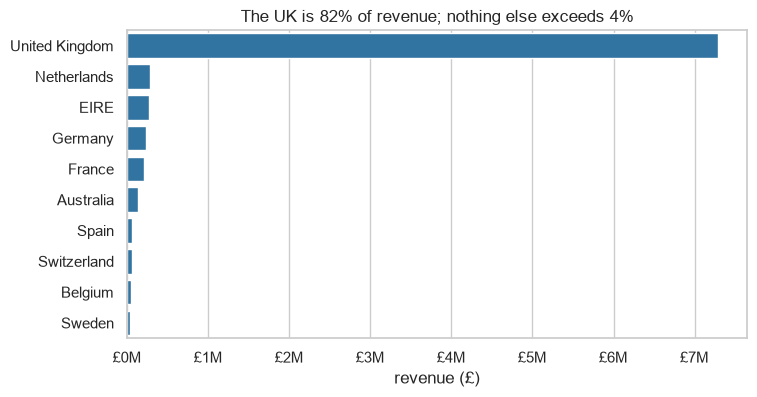

In [7]:
top = by_country.head(10)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=top.values, y=top.index, ax=ax, color="tab:blue")
ax.set(title="The UK is 82% of revenue; nothing else exceeds 4%", xlabel="revenue (£)", ylabel="")
ax.xaxis.set_major_formatter(lambda v, _: f"£{v/1e6:.0f}M")
plt.show()

**Finding:** one dominant category. When `Country` becomes a feature, nine in ten rows say "UK"; the other countries are too rare to learn much from individually.

## 5. Histogram: how is one number distributed?

Order value, 50 bins, linear scale first.

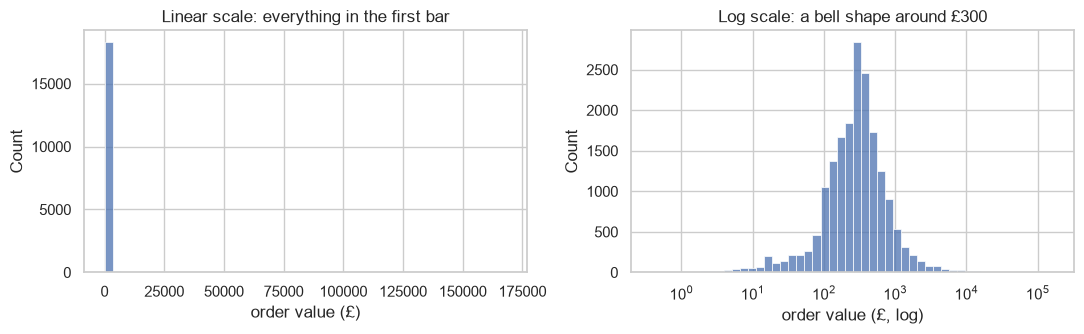

count     18532.0
mean        480.0
std        1678.0
min           0.0
25%         157.0
50%         303.0
75%         470.0
max      168470.0
Name: Revenue, dtype: float64


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(order_values, bins=50, ax=ax1)
ax1.set(title="Linear scale: everything in the first bar", xlabel="order value (£)")
sns.histplot(order_values, bins=50, log_scale=True, ax=ax2)
ax2.set(title="Log scale: a bell shape around £300", xlabel="order value (£, log)")
plt.tight_layout(); plt.show()
print(order_values.describe().round(0))

**Finding:** order values are **right-skewed**: median about £300, mean higher, a few orders in the tens of thousands. On a log scale the shape is roughly bell-shaped. Two consequences for later: report medians, not means; and models often prefer `log(spend)` as a target (Module 02).

## 6. Box plot: middle, spread, outliers, per group

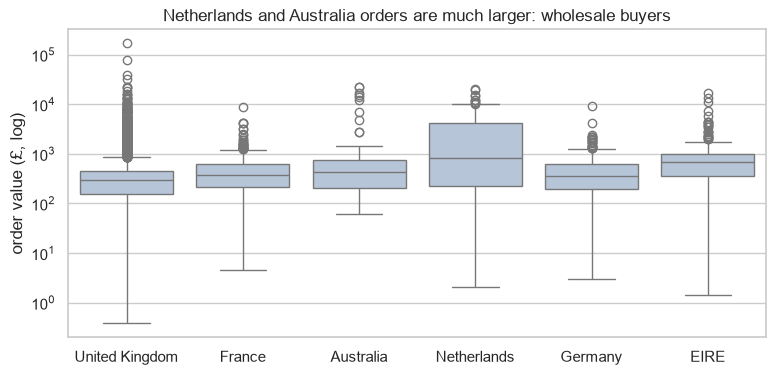

In [9]:
top6 = by_country.index[:6]
per_order = sales.groupby(["Invoice", "Country"])["Revenue"].sum().reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=per_order[per_order["Country"].isin(top6)], x="Country", y="Revenue", ax=ax, color="lightsteelblue")
ax.set_yscale("log")
ax.set(title="Netherlands and Australia orders are much larger: wholesale buyers", xlabel="", ylabel="order value (£, log)")
plt.show()

**Finding:** the UK box is low and tight (retail); the Netherlands and Australia boxes sit far higher (wholesale). The dots above each box are not errors; they are big customers. A model that treats all countries alike will be wrong about both.

## 7. Scatter: how do two numbers relate?

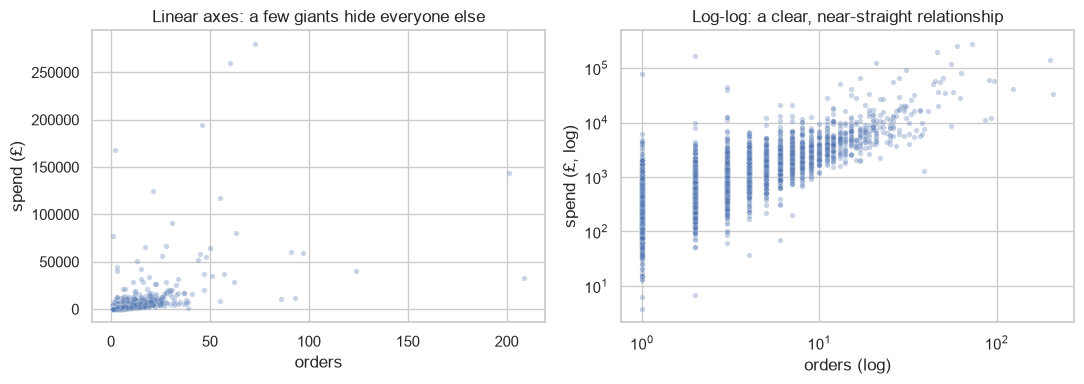

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=customers, x="orders", y="spend", alpha=.3, s=15, ax=ax1)
ax1.set(title="Linear axes: a few giants hide everyone else", xlabel="orders", ylabel="spend (£)")
sns.scatterplot(data=customers, x="orders", y="spend", alpha=.3, s=15, ax=ax2)
ax2.set(xscale="log", yscale="log", title="Log-log: a clear, near-straight relationship", xlabel="orders (log)", ylabel="spend (£, log)")
plt.tight_layout(); plt.show()

**Finding:** more orders, more spend, roughly proportionally, but with wide scatter at every level. `orders` will be a strong feature for predicting spend; it will not be the whole story.

## 8. Heatmap: how do many numbers relate at once?

Correlation (01.8) between every pair of numeric columns of the customer table, in one grid.

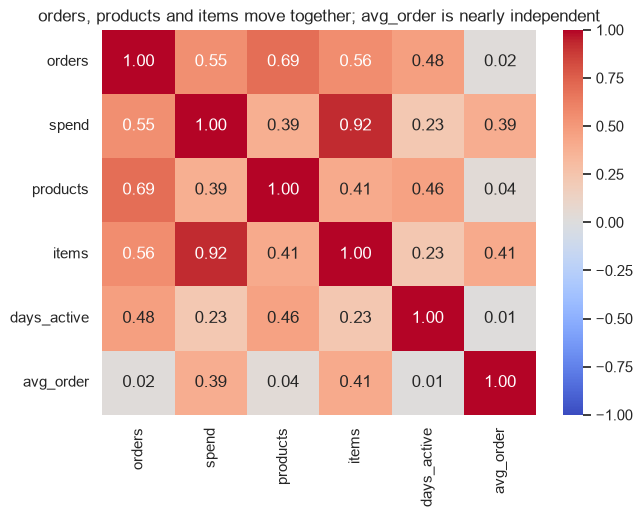

In [11]:
num = customers[["orders", "spend", "products", "items", "days_active", "avg_order"]]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set(title="orders, products and items move together; avg_order is nearly independent")
plt.show()

**Finding:** `orders`, `products` and `items` are strongly correlated (0.7–0.9): they measure the same thing, "how much this customer buys". `avg_order` is almost uncorrelated with all of them: it carries *different* information. When choosing features (Module 04), you will drop near-duplicates and keep the independent ones.

## 9. One figure, several panels

For reports you often want the charts side by side. `plt.subplots(rows, cols)` returns a grid of axes.

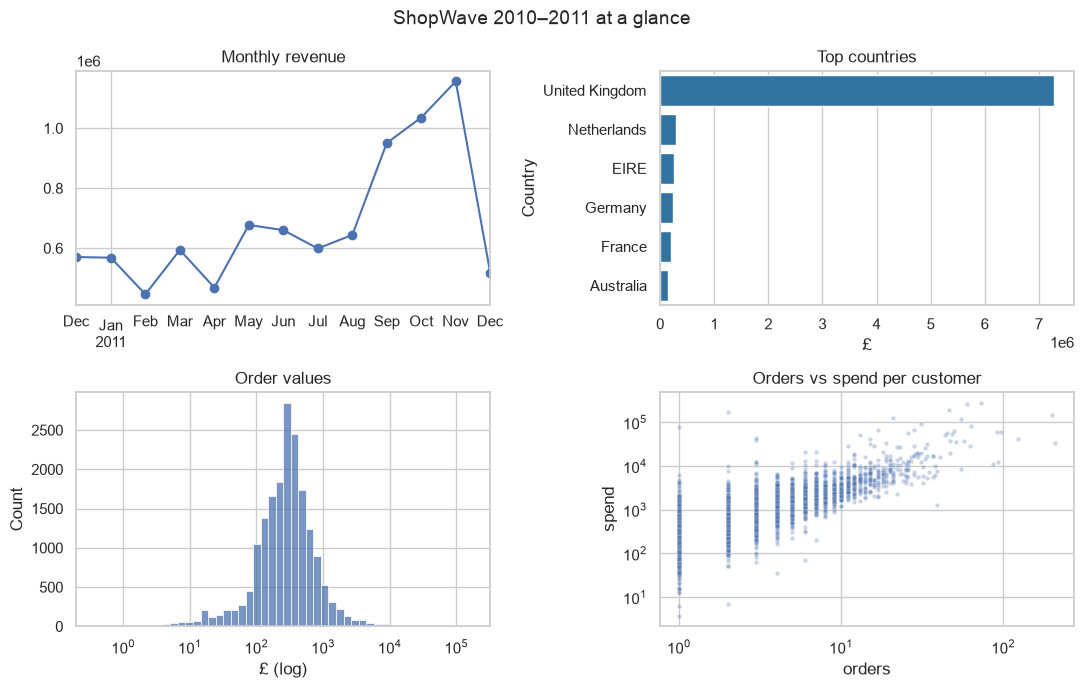

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
monthly.plot(ax=axes[0, 0], marker="o"); axes[0, 0].set(title="Monthly revenue", xlabel="")
sns.barplot(x=top.values[:6], y=top.index[:6], ax=axes[0, 1], color="tab:blue"); axes[0, 1].set(title="Top countries", xlabel="£")
sns.histplot(order_values, bins=50, log_scale=True, ax=axes[1, 0]); axes[1, 0].set(title="Order values", xlabel="£ (log)")
sns.scatterplot(data=customers, x="orders", y="spend", alpha=.3, s=10, ax=axes[1, 1])
axes[1, 1].set(xscale="log", yscale="log", title="Orders vs spend per customer")
fig.suptitle("ShopWave 2010–2011 at a glance", fontsize=14)
plt.tight_layout(); plt.show()

## Quiz answers

1. Histogram (distribution of one number). Bar chart (categories compared).
2. Box = 25th to 75th percentile; line = median; whiskers = furthest values within 1.5 × IQR of the box; dots = values beyond that (outliers).
3. When values span several orders of magnitude, so that small and large values are both visible and skewed data becomes bell-shaped.
4. Angles are harder to compare than lengths; small slices are unreadable; a sorted bar chart shows the same information with a ranking.
5. No. Correlation shows they move together. Both could be driven by a third thing (how long the customer has been a customer), and the direction is not given.

**Next:** [01.8 Statistics you need](../08-statistics-by-hand/)